# PingTracer export: a closer look

This notebook reads a CSV saved from PingTracer (**Export > Ping data to CSV**) and walks through it:

1. the numbers for each host
2. a histogram of ping times for each host
3. the latency spikes, numbered, with figures for how the hosts moved together
4. one numbered moment up close

It is a front end only. The work is done by the scripts beside it, which also run on their own from a terminal:
`ping_export.py` (reading and statistics), `ping_report.py`, `ping_histogram.py`, `ping_spikes.py`, and `test_ping_tools.py` to check them.

**To use it:** change `EXPORT` in the next cell to your file, then run every cell from the top. It needs Python 3.15.

In [1]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd()))   # the scripts sit in the same folder as this notebook

EXPORT = Path("../dist/analysis-demo/long-export.csv")   # <-- your export goes here
MIN_OUTAGE = 2         # lost pings in a row that count as an outage
SPIKE_ABOVE_MS = None  # how far above the median is a spike; None = 10 ms or 3x the usual spread, whichever is larger

## 1. Read the export

In [2]:
import ping_export
import ping_report
import ping_histogram
import ping_spikes

hosts = ping_export.read_export(EXPORT)
summaries = {host: ping_export.summarise(host, pings, MIN_OUTAGE) for host, pings in hosts.items()}

for host, pings in hosts.items():
    print(f"{len(pings):7d} pings   {host}")

   4500 pings   192.168.1.1
   4501 pings   100.92.0.1
   4501 pings   1.1.1.1
   4500 pings   130.56.67.33


## 2. The numbers

All times are in milliseconds.

- **baseline**: the fastest ping. The path with nothing queued.
- **worst 1%**: 99 pings in 100 were this fast or faster.
- **jitter**: the average change from one ping to the next.
- **queueing**: the average time above the baseline.

In [3]:
ms = ping_export.ms
columns = ("pings", "lost %", "baseline", "median", "mean", "95%", "worst 1%", "max", "jitter", "queueing")
print(f"{'host':<34}" + "".join(f"{c:>10}" for c in columns))
for host, s in summaries.items():
    row = (s.pings, f"{s.loss_percent:.2f}", ms(s.baseline), ms(s.median), ms(s.mean), ms(s.p95), ms(s.p99), ms(s.maximum), ms(s.jitter), ms(s.queueing_mean))
    print(f"{host[:33]:<34}" + "".join(f"{str(v):>10}" for v in row))

host                                   pings    lost %  baseline    median      mean       95%  worst 1%       max    jitter  queueing
192.168.1.1                             4500      0.00         0         1      2.34         6        16       114      1.93      2.34
100.92.0.1                              4501      0.00         1         3      3.87         8        18       116      2.28      2.87
1.1.1.1                                 4501      0.00         6         8      8.43        12        23       142      2.11      2.43
130.56.67.33                            4500      0.00       268       270    271.58       276       292       407      2.64      3.58


The same, in full, with every drop-out and any reply whose data came back altered:

In [4]:
for summary in summaries.values():
    print(ping_report.report(summary))
    print()

== 192.168.1.1
  4500 pings over 14 min 59 s  (2026-11-26 23:05:46 to 23:20:45)
  lost 0 (0.00%)
  latency ms: baseline 0  median 1  mean 2.34  95% 6  worst 1% 16  max 114
  jitter 1.93 ms   mean time above baseline (queueing) 2.34 ms
  no outages
  all reply data matched what was sent

== 100.92.0.1
  4501 pings over 14 min 59 s  (2026-11-26 23:05:46 to 23:20:46)
  lost 0 (0.00%)
  latency ms: baseline 1  median 3  mean 3.87  95% 8  worst 1% 18  max 116
  jitter 2.28 ms   mean time above baseline (queueing) 2.87 ms
  no outages
  all reply data matched what was sent

== 1.1.1.1
  4501 pings over 14 min 59 s  (2026-11-26 23:05:46 to 23:20:46)
  lost 0 (0.00%)
  latency ms: baseline 6  median 8  mean 8.43  95% 12  worst 1% 23  max 142
  jitter 2.11 ms   mean time above baseline (queueing) 2.43 ms
  no outages
  all reply data matched what was sent

== 130.56.67.33
  4500 pings over 14 min 59 s  (2026-11-26 23:05:46 to 23:20:45)
  lost 0 (0.00%)
  latency ms: baseline 268  median 270  me

## 3. Histograms

One picture per host. The top panel counts how many pings took each time, with the baseline, median and worst 1% marked.
The bottom panel is the same pings in the order they happened, with lost pings in red.

If a few pings are far slower than the rest they are left off the histogram, with a note saying how many and how slow, so the main shape stays readable. They still appear in the bottom panel.

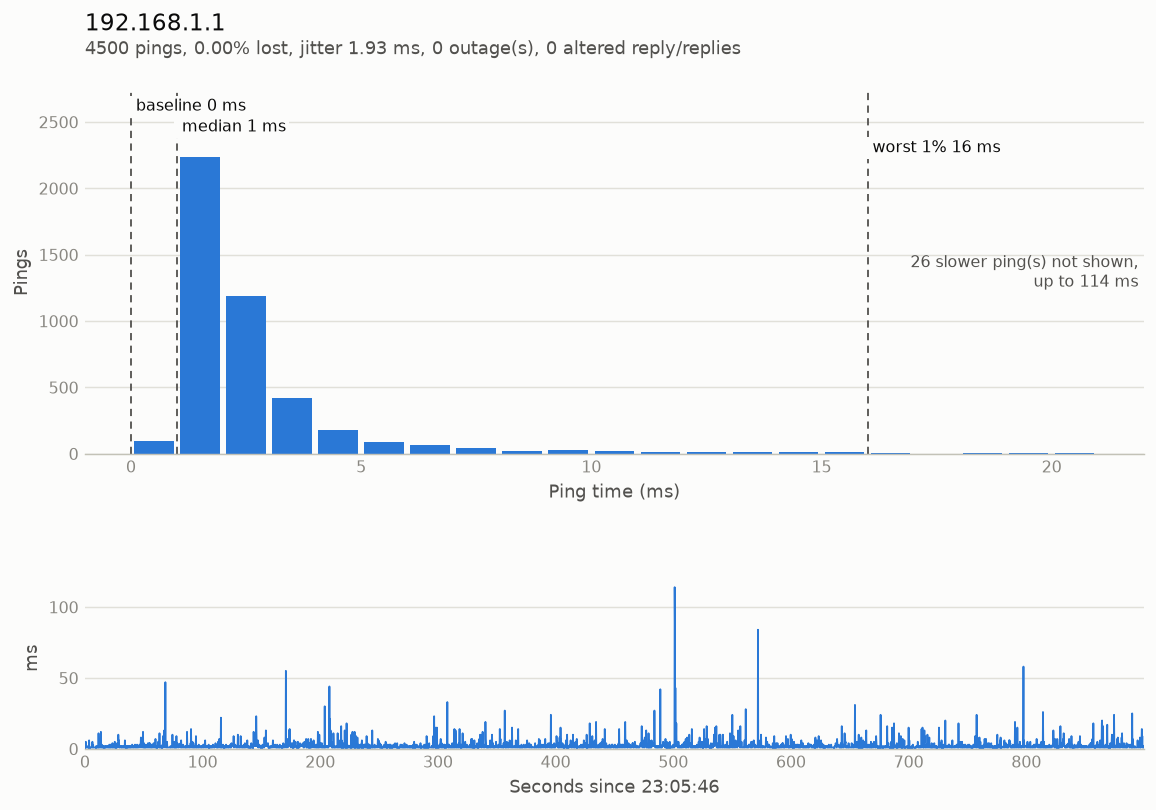

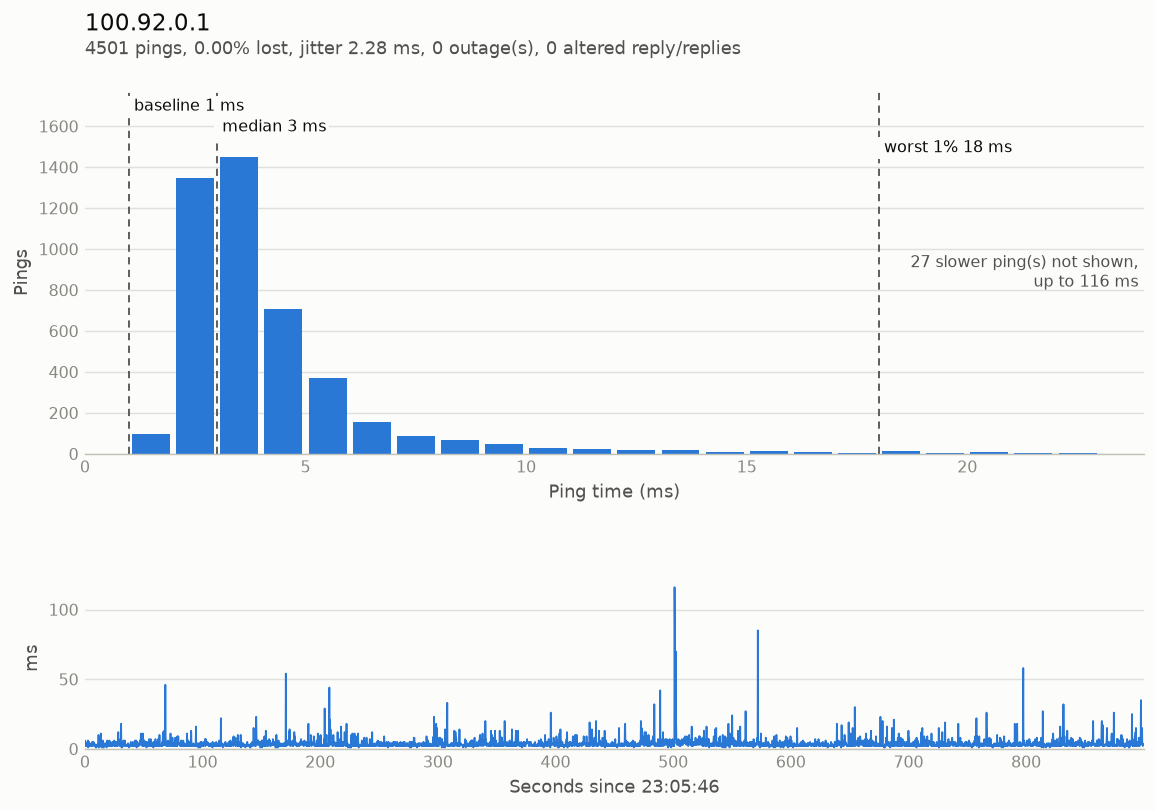

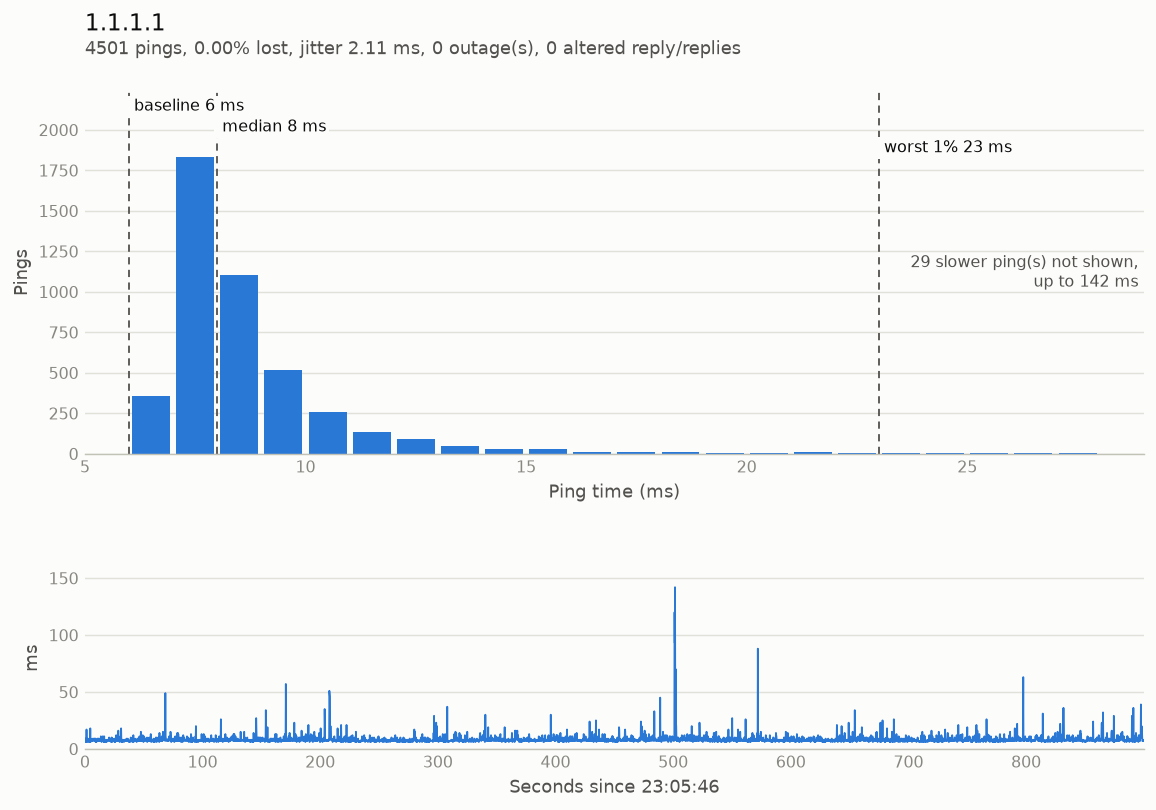

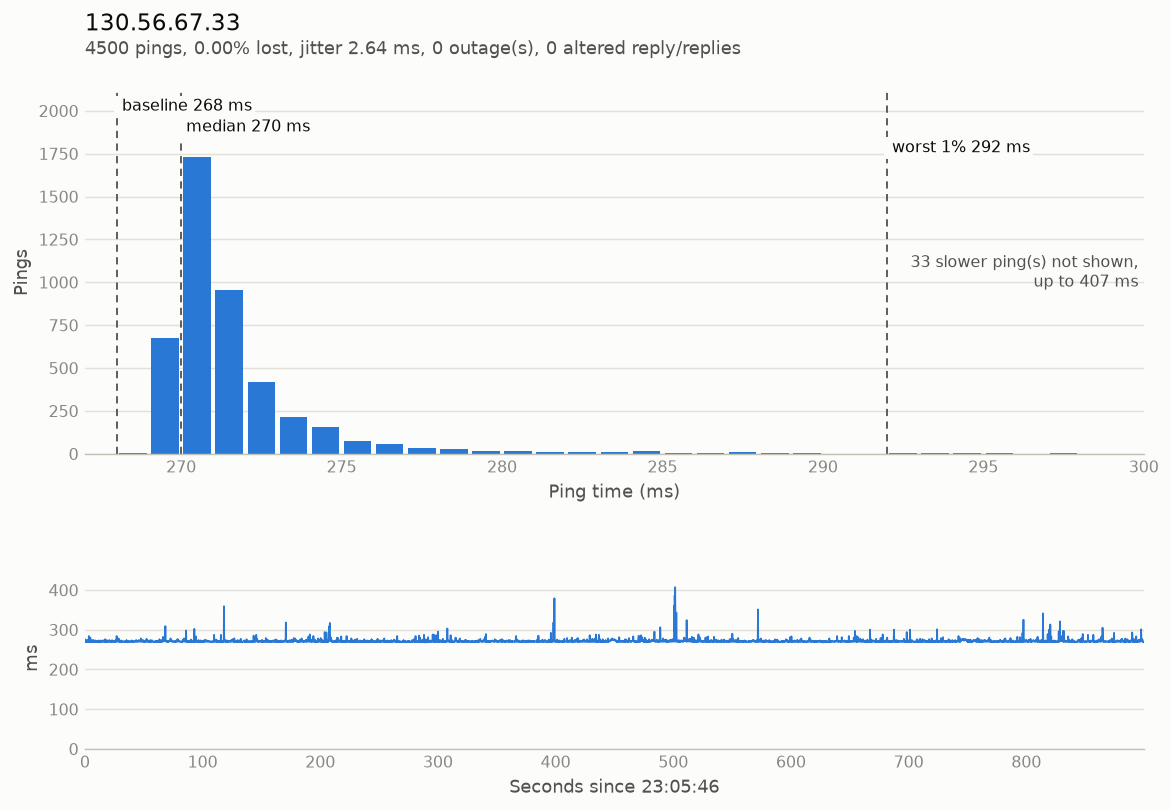

In [5]:
import matplotlib.pyplot as plt

for host, pings in hosts.items():
    figure = ping_histogram.figure_host(summaries[host], pings, ping_export.choose_times(pings))
    if figure is None:
        print(f"{host}: no replies, nothing to draw")
    else:
        plt.show()

## 4. Spikes

A spike is a ping well above the host's own median. Spike pings less than a second apart count as one spike.

Every moment at which something spiked gets a number (**M1, M2, ...**), used in the list, in the picture and in section 5, so any one of them can be pointed at.

The last block puts figures on how each host moved with the first host in the file:

- **spikes together**: how many of its spikes fell in a moment the first host shared
- **by chance**: how many would be expected to if the two were unrelated, and the probability of seeing at least as many as were seen
- **correlation**: Pearson's r between the two hosts' ping times, round by round (+1 = rise and fall together, 0 = unrelated)
- **shared delay**: of all this host's time above its own median, the share that was matched in the same round on the first host

High figures point at or before the first host; low ones point further out. They come from timing alone and are not proof of a cause.

In [6]:
spikes = ping_spikes.analyse(hosts, above_ms=SPIKE_ABOVE_MS)
relations = ping_spikes.relate(hosts, spikes)
print(ping_spikes.report(spikes, relations))

Moments: 141 in all, 66 on more than one host   (peak above each host's own median)
  M1   23:05:49.516   0.0 s  1 of 4 hosts   130.56.67.33 +14 ms
  M2   23:05:59.724   0.0 s  1 of 4 hosts   192.168.1.1 +11 ms
  M3   23:06:13.128   0.0 s  1 of 4 hosts   130.56.67.33 +14 ms
  M4   23:06:16.918   0.0 s  1 of 4 hosts   100.92.0.1 +15 ms
  M5   23:06:35.523   0.0 s  1 of 4 hosts   192.168.1.1 +11 ms
  M6   23:06:52.523   0.0 s  1 of 4 hosts   130.56.67.33 +12 ms
  M7   23:06:53.529   1.0 s  4 of 4 hosts   192.168.1.1 +46 ms | 100.92.0.1 +43 ms | 1.1.1.1 +41 ms | 130.56.67.33 +39 ms
  M8   23:07:12.118   0.0 s  1 of 4 hosts   130.56.67.33 +28 ms
  M9   23:07:12.927   0.0 s  1 of 4 hosts   192.168.1.1 +11 ms
  M10  23:07:16.321   0.0 s  1 of 4 hosts   192.168.1.1 +13 ms
  M11  23:07:19.118   0.0 s  1 of 4 hosts   130.56.67.33 +32 ms
  M12  23:07:20.530   0.0 s  3 of 4 hosts   100.92.0.1 +13 ms | 1.1.1.1 +12 ms | 130.56.67.33 +13 ms
  M13  23:07:35.921   0.0 s  1 of 4 hosts   130.56.67.33 +1

Every host on one time axis. Orange diamonds are spike pings, each labelled with its moment number. The dashed line is each host's spike threshold, and a shaded band marks a moment shared by more than one host.

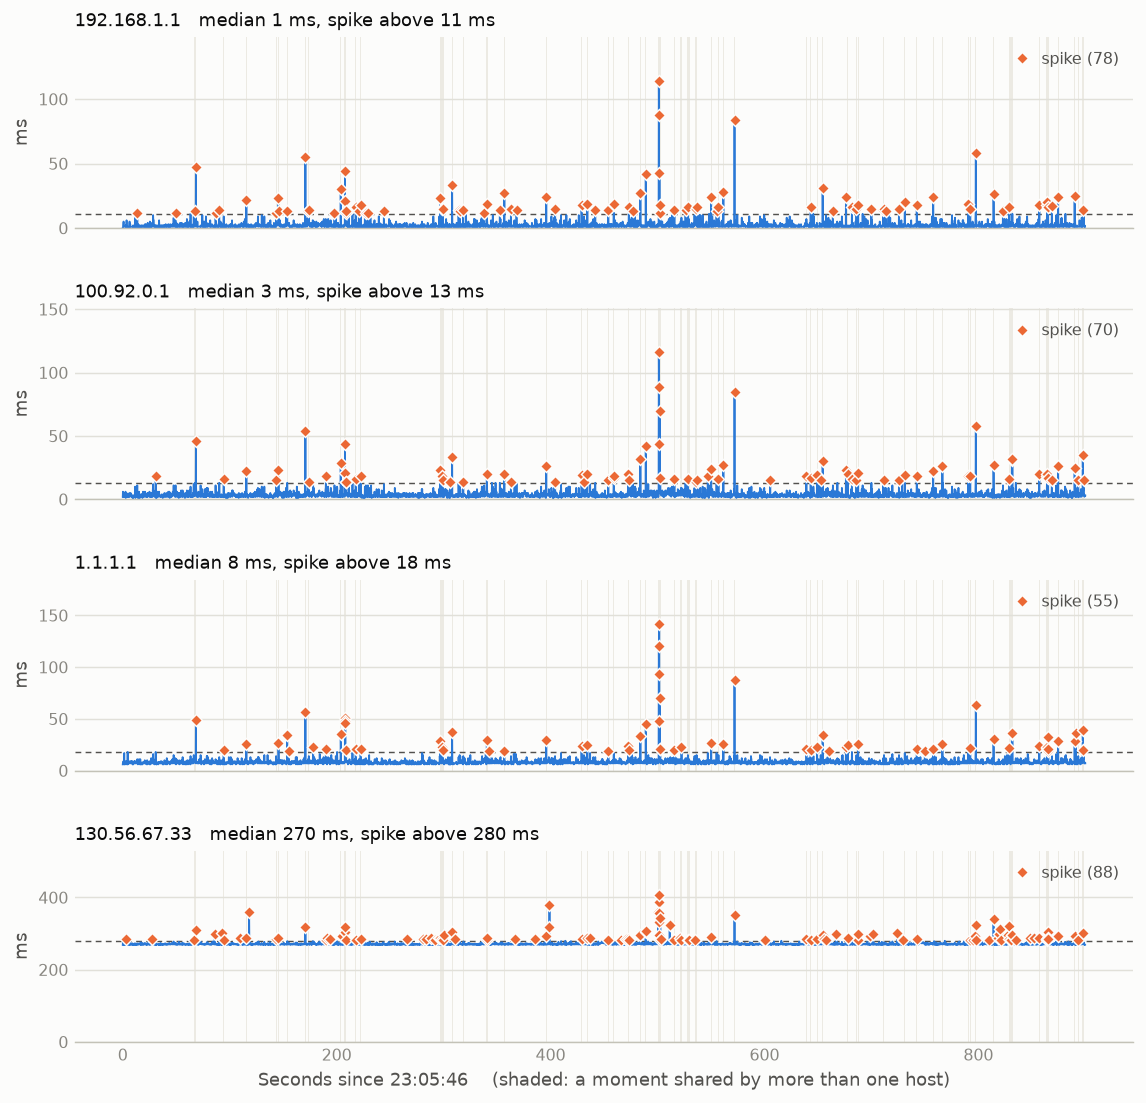

In [7]:
figure = ping_spikes.figure_spikes(hosts, spikes)
if figure is None:
    print("no replies, nothing to draw")
else:
    plt.show()

## 5. One moment up close

Lists every host's pings for a couple of seconds either side of one moment, so the order things happened in can be read off directly. Set `MOMENT` to a number from the list above (5 for M5); left as `None` it takes the moment with the highest spike.

In [8]:
from datetime import timedelta

MOMENT = None          # a moment number from the list above, or None for the one with the highest spike
WINDOW_SECONDS = 2.0

moments = ping_spikes.list_moments(spikes)
if not moments:
    print("no spikes in this file")
else:
    if MOMENT is None:
        chosen = max(moments, key=lambda m: max(spike.above_ms for spike in m.spikes))
    else:
        chosen = next(m for m in moments if m.number == MOMENT)
    print(f"M{chosen.number}: {chosen.start:%H:%M:%S.%f}"[:-3] + f", lasting {ping_export.duration_text(chosen.seconds)}, on {len(chosen.hosts)} of {len(hosts)} hosts")
    for spike in chosen.spikes:
        print(f"   {spike.host}: peak {ms(spike.peak_ms)} ms, {ms(spike.above_ms)} ms above its median")
    print(f"Pings from {WINDOW_SECONDS:g} s before it to {WINDOW_SECONDS:g} s after it (* = spike, lost = no reply):")
    print()
    thresholds = {h.host: h.threshold_ms for h in spikes}
    for host, pings in hosts.items():
        print(f"  {host}   (median {ms(summaries[host].median)} ms)")
        for ping in pings:
            if chosen.start - timedelta(seconds=WINDOW_SECONDS) <= ping.sent <= chosen.end + timedelta(seconds=WINDOW_SECONDS):
                offset = (ping.sent - chosen.start).total_seconds()
                if not ping.replied:
                    value, mark = "lost", ""
                else:
                    value, mark = f"{ms(ping.rtt_ms)} ms", " *" if ping.rtt_ms > thresholds[host] else ""
                print(f"    {offset:+7.2f} s  {value:>8}{mark}")
        print()

M74: 23:14:06.933, lasting 2.0 s, on 4 of 4 hosts
   130.56.67.33: peak 407 ms, 137 ms above its median
   192.168.1.1: peak 114 ms, 113 ms above its median
   100.92.0.1: peak 116 ms, 113 ms above its median
   1.1.1.1: peak 142 ms, 134 ms above its median
Pings from 2 s before it to 2 s after it (* = spike, lost = no reply):

  192.168.1.1   (median 1 ms)
      -1.81 s      2 ms
      -1.60 s      1 ms
      -1.42 s      2 ms
      -1.21 s      1 ms
      -1.00 s      2 ms
      -0.81 s      3 ms
      -0.62 s      1 ms
      -0.41 s      1 ms
      -0.21 s      1 ms
      -0.00 s      1 ms
      +0.20 s      1 ms
      +0.39 s    114 ms *
      +0.60 s     88 ms *
      +0.79 s      2 ms
      +1.00 s     43 ms *
      +1.19 s      7 ms
      +1.40 s      2 ms
      +1.59 s     12 ms *
      +1.79 s     18 ms *
      +2.00 s      4 ms
      +2.20 s      3 ms
      +2.38 s      2 ms
      +2.59 s      2 ms
      +2.79 s      3 ms
      +3.00 s      1 ms
      +3.19 s      5 ms
      

## Checking the scripts

`test_ping_tools.py` builds an export with known contents and compares every figure with a value worked out a second way, and with NumPy where it is installed. Run it from a terminal in this folder:

```
py -3.15 test_ping_tools.py
```